# Validación del dataset

Bloques «Primera corrida», «Validación» y «Ajuste» del Objetivo 1 (`docs/Validacion_dataset.docx`). El cuaderno:

- revisa la primera corrida completa (dataset v0.1): vacíos, rangos, reglas y la forma de las duraciones;
- calcula los 22 indicadores del sistema de variables (hoja «Indicadores» del Excel) en el v0.1 y en el v0.2, que
  corrige lo que encontró la validación del v0.1 (`src/generador/validacion.py`);
- guarda el resumen y las tablas de detalle en `resultados/tablas/` (`validacion_<versión>_resumen.csv` y
  `validacion_<versión>.xlsx`) y las figuras del informe en `resultados/figuras/`.

Necesita los dos datasets, que se generan con `python -m src.generador.generar --version v0.1` y `--version v0.2`
(unos 8 y 10 minutos). El v0.1 queda en `datos/sinteticos/borradores/v0.1/`, que no se sube al repositorio. El
cuaderno tarda unos 17 minutos, casi todos en la sensibilidad de la capacidad, al final.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from src.generador import duraciones as du, escenarios, generar, registro, validacion
from src.generador.recursos import MIN_POR_DIA, MIN_POR_SEMANA, TECNICAS

TABLAS, FIGURAS = RAIZ / "resultados" / "tablas", RAIZ / "resultados" / "figuras"
VERSIONES = ["v0.1", "v0.2"]
ESCENARIOS = list(escenarios.ESCENARIOS)
DESDE = escenarios.CALENTAMIENTO_DIAS * MIN_POR_DIA
datos = {v: generar.cargar_version(v) for v in VERSIONES}
pd.DataFrame({v: {"corridas": len(d[2]), "registros": len(d[0]), "eventos de equipos": len(d[1])}
              for v, d in datos.items()})

,v0.1,v0.2
corridas,9,9
registros,149517,139209
eventos de equipos,6195,6195


## Primera corrida (v0.1): revisión rápida

Nueve corridas de 52 semanas (tres escenarios por tres semillas) con los valores del 29 de octubre: PERT clásica
(λ = 4), ρ = 0,5 y sin preparación ni idoneidad del sistema, cuyos tres puntos estaban pendientes. Antes de los
indicadores, lo básico: cuántos registros salen, si hay vacíos, si algún valor queda fuera de su rango y si todos
cumplen las reglas del diccionario.

In [2]:
reg01, ev01, res01 = datos["v0.1"]
corridas01 = pd.DataFrame(res01).set_index(["escenario", "semilla"]).loc[ESCENARIOS]
corridas01[["muestras", "ensayos_pedidos", "registros", "registros_que_cumplen_las_reglas", "reanalisis",
            "interrumpidos", "fallas", "ventanas", "ejecuciones_en_cola_al_cierre", "segundos"]]

muestras  ensayos_pedidos  registros  \
escenario semilla                                         
baja      2026         8998            10679      10941   
          2027         8798            10468      10693   
          2028         8896            10709      10947   
base      2026        12909            15384      15740   
          2027        12806            15245      15560   
          2028        12904            15534      15866   
alta      2026        19299            23087      23591   
          2027        18861            22421      22864   
          2028        19042            22853      23315   

                   registros_que_cumplen_las_reglas  reanalisis  \
escenario semilla                                                 
baja      2026                                10941         246   
          2027                                10693         205   
          2028                                10947         214   
base      2026                                15740         337   
          2027                                15560         292   
          2028                                15866         321   
alta      2026                                23591         498   
          2027                                22864         430   
          2028                                23315         474   

                   interrumpidos  fallas  ventanas  \
escenario semilla                                    
baja      2026                17     409       280   
          2027                21     435       280   
          2028                27     381       280   
base      2026                22     409       280   
          2027                31     435       280   
          2028                22     381       280   
alta      2026                45     409       280   
          2027                37     435       280   
          2028                37     381       280   

                   ejecuciones_en_cola_al_cierre  segundos  
escenario semilla                                           
baja      2026                                 0      35.7  
          2027                                 0      31.8  
          2028                                 1      32.6  
base      2026                                 0      49.5  
          2027                                 3      48.2  
          2028                                 6      48.7  
alta      2026                                39      77.9  
          2027                                21      73.2  
          2028                                41      75.6

In [3]:
obligatorios = [c for c in registro.CAMPOS_REGISTRO if c not in registro.OPCIONALES]
fuera01 = validacion.fuera_de_rango(reg01, 52 * 7 * MIN_POR_DIA)
reglas01 = registro.chequear_registro(reg01)
pd.Series({"vacíos en campos obligatorios": int(reg01[obligatorios].isna().sum().sum()),
           "vacíos en id_actividad_origen fuera del intento 1": int(reg01.loc[reg01["intento"] > 1, "id_actividad_origen"].isna().sum()),
           "valores fuera de rango": int(fuera01.to_numpy().sum()),
           "registros que no cumplen alguna regla": int((~reglas01.all(axis=1)).sum())})

vacíos en campos obligatorios                        0
vacíos en id_actividad_origen fuera del intento 1    0
valores fuera de rango                               0
registros que no cumplen alguna regla                0
dtype: int64

## Indicadores del v0.1 y del v0.2

`validacion.validar` calcula los 22 indicadores con sus tablas de detalle y un veredicto: «cumple» o «no cumple»
cuando el indicador tiene criterio de aceptación y «se reporta» cuando la referencia es un orden de magnitud o una
tendencia. Las colas, la carga y el tiempo en el sistema se miden sin las dos primeras semanas, en que el laboratorio arranca vacío.

In [4]:
val = {v: validacion.validar(datos[v][0], datos[v][1], v) for v in VERSIONES}
for v in VERSIONES:
    validacion.guardar(val[v], v)
resumen = val["v0.2"]["resumen"][["codigo", "indicador"]].assign(
    **{f"veredicto {v}": val[v]["resumen"]["veredicto"] for v in VERSIONES})
resumen

,codigo,indicador,veredicto v0.1,veredicto v0.2
0,T1,Tiempo optimista por actividad,cumple,cumple
1,T2,Tiempo más probable,cumple,cumple
2,T3,Tiempo pesimista,cumple,cumple
3,T4,Duración simulada de la actividad,cumple,cumple
4,T5,Media y dispersión de las duraciones generadas,cumple,cumple
5,H1,Número de analistas disponibles,cumple,cumple
6,H2,Calificación o elegibilidad del analista por a...,cumple,cumple
7,H3,Disponibilidad temporal del analista,cumple,cumple
8,H4,Carga asignada al analista,se reporta,se reporta
9,M1,Número de equipos disponibles,cumple,cumple


In [5]:
pd.set_option("display.max_colwidth", 400)
pd.DataFrame({v: val[v]["resumen"].set_index("codigo")["valor"] for v in VERSIONES})

,v0.1,v0.2
codigo,,
T1,"100,0 % de los registros con el valor que dan la hoja Duraciones y el catálogo, y ordenado","100,0 % de los registros con el valor que dan la hoja Duraciones y el catálogo, y ordenado"
T2,"100,0 % de los registros con el valor que dan la hoja Duraciones y el catálogo, y ordenado","100,0 % de los registros con el valor que dan la hoja Duraciones y el catálogo, y ordenado"
T3,"100,0 % de los registros con el valor que dan la hoja Duraciones y el catálogo, y ordenado","100,0 % de los registros con el valor que dan la hoja Duraciones y el catálogo, y ordenado"
T4,"100,0 % de los registros con la duración entre sus tiempos optimista y pesimista corregidos y igual a la suma de sus tareas","100,0 % de los registros con la duración entre sus tiempos optimista y pesimista corregidos y igual a la suma de sus tareas"
T5,"Media de cada tarea a 2,8 errores estándar o menos de su media BetaPERT esperada (diferencia de 1,4 % o menos); preparación y corrida de HPLC y GC frente a la Tabla 6: GC preparacion -20,7 %, GC corrida 0,4 %, HPLC preparacion -7,3 %, HPLC corrida 1,1 %","Media de cada tarea a 3,1 errores estándar o menos de su media BetaPERT esperada (diferencia de 1,8 % o menos); preparación y corrida de HPLC y GC frente a la Tabla 6: GC preparacion -2,3 %, GC corrida -0,1 %, HPLC preparacion 0,2 %, HPLC corrida 1,0 %; HPLC y GC con alistamiento, sin procesamiento: 268 a 672 min"
H1,"Entre 2 y 14 analistas en turno (máximo en fin de semana: 2); calificados libres al llegar, en promedio: alta 0,9, baja 3,1, base 2,2","Entre 2 y 14 analistas en turno (máximo en fin de semana: 2); calificados libres al llegar, en promedio: alta 0,5, baja 2,4, base 1,1"
H2,"100,0 % de los registros con un analista calificado del nivel exigido","100,0 % de los registros con un analista calificado del nivel exigido"
H3,"Horas por semana: turno 1 56,0, turno 2 37,5, turno 3 40,0; 886,0 horas-analista por semana (diseño: 886); 100,0 % de las ejecuciones empiezan con su analista en turno","Horas por semana: turno 1 56,0, turno 2 37,5, turno 3 40,0; 886,0 horas-analista por semana (diseño: 886); 100,0 % de las ejecuciones empiezan con su analista en turno"
H4,"Trabajo asignado entre horas en turno, promedio de los analistas: alta 77,3 %, baja 36,4 %, base 52,3 %; percentil 90: alta 94,1 %, baja 55,6 %, base 71,5 %","Trabajo asignado entre horas en turno, promedio de los analistas: alta 86,7 %, baja 50,3 %, base 72,3 %; percentil 90: alta 98,6 %, baja 72,9 %, base 91,3 %"


## Figuras del informe

Numeradas como en el informe (docs/Validacion_dataset.docx). Mismo estilo que los cuadernos 01 y 02. Colores: la versión vigente (v0.2) en azul, la anterior en gris y la fuente
en negro; los escenarios, del azul claro (baja) al oscuro (alta).

In [6]:
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Inter", "Helvetica", "Arial", "Liberation Sans", "DejaVu Sans"],
    "font.size": 8, "axes.titlesize": 8.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8, "xtick.color": "#c3c2b7", "xtick.labelcolor": "#52514e",
    "ytick.color": "#c3c2b7", "ytick.labelcolor": "#52514e", "axes.labelcolor": "#52514e",
    "figure.facecolor": "white", "axes.facecolor": "white", "legend.frameon": False,
})
COLOR = {"v0.1": "#898781", "v0.2": "#2a78d6", "fuente": "#0b0b0b"}
COLOR_ESCENARIO = {"baja": "#86b6ef", "base": "#2a78d6", "alta": "#104281"}


def limpiar(eje):
    for lado in ("top", "right"):
        eje.spines[lado].set_visible(False)


def coma(x, d=0):
    return f"{x:.{d}f}".replace(".", ",")

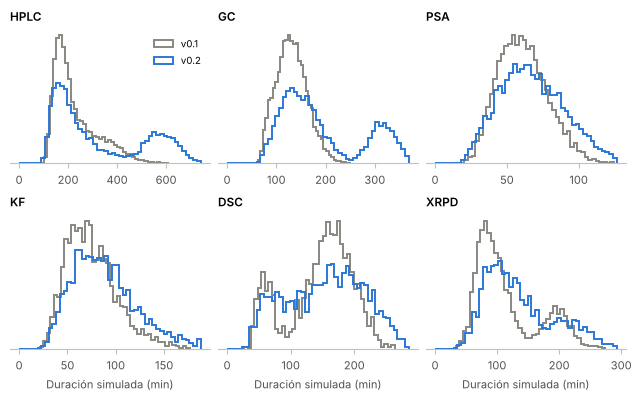

In [7]:
# Figura 1: duración simulada por técnica, v0.1 y v0.2 (escenario base, ejecuciones terminadas)
fig, ejes = plt.subplots(2, 3, figsize=(6.3, 3.9), layout="constrained")
for eje, tecnica in zip(ejes.flat, TECNICAS):
    for v in VERSIONES:
        r = datos[v][0]
        d = r.loc[r["escenario"].eq("base") & r["tecnica"].eq(tecnica) & r["resultado"].ne("interrumpido"),
                  "duracion_simulada"]
        eje.hist(d, bins=np.linspace(0, d.quantile(0.995) if v == "v0.2" else d.max(), 50), density=True,
                 histtype="step", linewidth=1.4, color=COLOR[v], label=v)
    eje.set_title(tecnica)
    eje.set_yticks([])
    limpiar(eje)
    eje.spines["left"].set_visible(False)
for eje in ejes[1]:
    eje.set_xlabel("Duración simulada (min)")
ejes[0, 0].legend(loc="upper right", fontsize=7)
fig.savefig(FIGURAS / "validacion_duraciones.png", dpi=300)
plt.show()

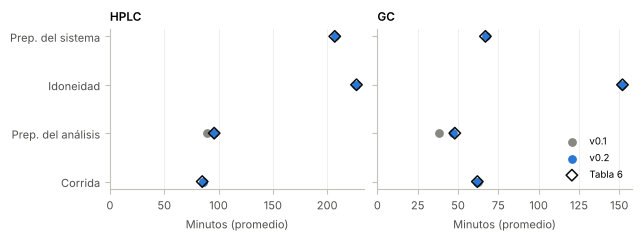

In [8]:
# Figura 2: tareas de HPLC y GC frente a los promedios de Costigliola et al. (2017, Tabla 6)
tareas = ["t_prep_sistema", "t_idoneidad", "t_preparacion", "t_corrida"]
nombres = {"t_prep_sistema": "Prep. del sistema", "t_idoneidad": "Idoneidad", "t_preparacion": "Prep. del análisis",
           "t_corrida": "Corrida"}
fuente = du.tiempos_promedio_fuente()
fig, ejes = plt.subplots(1, 2, figsize=(6.3, 2.3), layout="constrained", sharey=True)
for eje, tecnica in zip(ejes, ["HPLC", "GC"]):
    y = np.arange(len(tareas))[::-1]
    for v, marca in (("v0.1", "o"), ("v0.2", "o")):
        f = val[v]["T5"]["tablas"]["frente_a_la_fuente"]
        f = f[f["tecnica"].eq(tecnica)].set_index("tarea")["media_simulada"].reindex(tareas)
        eje.scatter(f.to_numpy(), y, s=28, color=COLOR[v], label=v, zorder=3, marker=marca)
    eje.scatter(fuente.loc[tecnica, tareas].to_numpy(), y, s=34, marker="D", facecolors="none",
                edgecolors=COLOR["fuente"], linewidths=1.1, label="Tabla 6", zorder=4)
    eje.set_yticks(y, [nombres[t] for t in tareas])
    eje.set_title(tecnica)
    eje.set_xlabel("Minutos (promedio)")
    eje.set_xlim(left=0)
    eje.grid(axis="x", color="#ecebe6", linewidth=0.6)
    eje.set_axisbelow(True)
    limpiar(eje)
ejes[1].legend(loc="lower right", fontsize=7)
fig.savefig(FIGURAS / "validacion_tiempos_fuente.png", dpi=300)
plt.show()

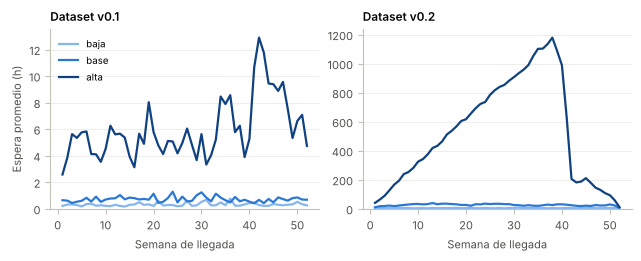

In [9]:
# Figura 5: espera promedio por semana de llegada y escenario (promedio de las tres semillas)
fig, ejes = plt.subplots(1, 2, figsize=(6.3, 2.5), layout="constrained")
for eje, v in zip(ejes, VERSIONES):
    r = datos[v][0]
    semanal = (r.assign(semana=(r["llegada"] // MIN_POR_SEMANA).astype(int) + 1)
               .groupby(["escenario", "semana"])["espera"].mean() / 60)
    for e in ESCENARIOS:
        s = semanal.loc[e]
        eje.plot(s.index, s.to_numpy(), color=COLOR_ESCENARIO[e], linewidth=1.6, label=e)
    eje.set_title(f"Dataset {v}")
    eje.set_xlabel("Semana de llegada")
    eje.set_ylim(bottom=0)
    eje.grid(axis="y", color="#ecebe6", linewidth=0.6)
    eje.set_axisbelow(True)
    limpiar(eje)
ejes[0].set_ylabel("Espera promedio (h)")
ejes[0].legend(loc="upper left", fontsize=7)
fig.savefig(FIGURAS / "validacion_espera_semanal.png", dpi=300)
plt.show()

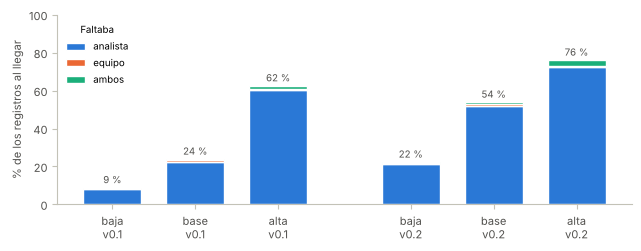

In [10]:
# Figura 3: actividades restringidas por falta de recursos al llegar (C4), por escenario y versión
partes = {"analista": "#2a78d6", "equipo": "#eb6834", "ambos": "#1baf7a"}
fig, eje = plt.subplots(figsize=(6.3, 2.4), layout="constrained")
etiquetas, x = [], 0
for v in VERSIONES:
    tabla = val[v]["C4"]["tablas"]["por_escenario"].loc[ESCENARIOS]
    for e in ESCENARIOS:
        abajo = 0.0
        for parte, color in partes.items():
            alto = float(tabla.at[e, parte])
            eje.bar(x, alto, bottom=abajo, width=0.7, color=color, edgecolor="white", linewidth=1.0,
                    label=parte if x == 0 else None)
            abajo += alto
        eje.text(x, abajo + 1.2, coma(abajo) + " %", ha="center", va="bottom", fontsize=7, color="#52514e")
        etiquetas.append(f"{e}\n{v}")
        x += 1
    x += 0.6
posiciones = [i + (0.6 if i >= 3 else 0) for i in range(6)]
eje.set_xticks(posiciones, etiquetas)
eje.set_ylabel("% de los registros al llegar")
eje.set_ylim(0, 100)
eje.legend(loc="upper left", fontsize=7, title="Faltaba", title_fontsize=7)
limpiar(eje)
fig.savefig(FIGURAS / "validacion_restringidas.png", dpi=300)
plt.show()

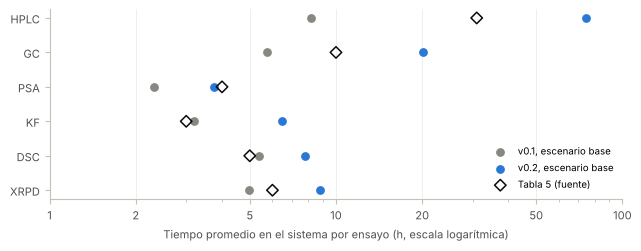

In [11]:
# Figura 4: tiempo en el sistema por técnica (por ensayo, escenario base) frente a Costigliola et al. (2017, Tabla 5)
fig, eje = plt.subplots(figsize=(6.3, 2.4), layout="constrained")
y = np.arange(len(TECNICAS))[::-1]
for v in VERSIONES:
    t = val[v]["V1"]["tablas"]["tiempo_en_sistema_horas"]["ensayo_base"].reindex(TECNICAS)
    eje.scatter(t.to_numpy(), y, s=28, color=COLOR[v], label=f"{v}, escenario base", zorder=3)
fuente5 = validacion.tiempo_en_sistema_fuente().reindex(TECNICAS)
eje.scatter(fuente5.to_numpy(), y, s=34, marker="D", facecolors="none", edgecolors=COLOR["fuente"], linewidths=1.1,
            label="Tabla 5 (fuente)", zorder=4)
eje.set_yticks(y, TECNICAS)
eje.set_xscale("log")
eje.set_xticks([1, 2, 5, 10, 20, 50, 100], ["1", "2", "5", "10", "20", "50", "100"])
eje.set_xlabel("Tiempo promedio en el sistema por ensayo (h, escala logarítmica)")
eje.grid(axis="x", color="#ecebe6", linewidth=0.6)
eje.set_axisbelow(True)
eje.legend(loc="lower right", fontsize=7)
limpiar(eje)
fig.savefig(FIGURAS / "validacion_tiempo_en_sistema.png", dpi=300)
plt.show()

## Lo que cambió del v0.1 al v0.2

Tablas para el informe: tiempo en el sistema por técnica, carga de los analistas, ejecuciones que quedan en cola al
cierre y entregas tarde por tipo de muestra.

In [12]:
tes = pd.concat([val[v]["V1"]["tablas"]["tiempo_en_sistema_horas"][[f"ensayo_{e}" for e in ESCENARIOS]]
                 .rename(columns=lambda c: f"{v} {c.removeprefix('ensayo_')}") for v in VERSIONES], axis=1)
tes = tes.join(validacion.tiempo_en_sistema_fuente().rename("Tabla 5"))
tes.to_csv(TABLAS / "validacion_tiempo_en_sistema.csv")
tes.round(1)

,v0.1 baja,v0.1 base,v0.1 alta,v0.2 baja,v0.2 base,v0.2 alta,Tabla 5
tecnica,,,,,,,
DSC,4.8,5.4,8.5,6.2,7.8,93.9,5.0
GC,4.8,5.7,9.7,10.5,20.2,850.7,10.0
HPLC,7.3,8.2,20.1,21.9,74.4,1117.0,31.0
KF,2.7,3.2,7.6,4.0,6.5,95.0,3.0
PSA,1.9,2.3,4.2,2.5,3.8,71.2,4.0
XRPD,4.0,5.0,8.5,5.9,8.8,61.7,6.0


In [13]:
carga = pd.concat({v: val[v]["H4"]["tablas"]["por_escenario"][["mean", "50%", "90%", "max"]] for v in VERSIONES})
cola = pd.concat({v: pd.DataFrame(datos[v][2]).groupby("escenario")[
    ["ensayos_pedidos", "registros", "ejecuciones_en_cola_al_cierre"]].mean() for v in VERSIONES})
carga.round(3), cola.round(0)

(                 mean    50%    90%    max
      escenario                            
 v0.1 alta       0.773  0.855  0.941  1.010
      baja       0.364  0.383  0.556  0.802
      base       0.523  0.566  0.715  0.910
 v0.2 alta       0.867  0.939  0.986  1.108
      baja       0.503  0.542  0.729  0.943
      base       0.723  0.807  0.913  1.041,
                 ensayos_pedidos  registros  ejecuciones_en_cola_al_cierre
      escenario                                                           
 v0.1 alta               22787.0    23257.0                           34.0
      baja               10619.0    10860.0                            0.0
      base               15388.0    15722.0                            3.0
 v0.2 alta               22787.0    19866.0                         3363.0
      baja               10619.0    10863.0                            5.0
      base               15388.0    15674.0                           61.0)

In [14]:
def tarde(r):
    v = r[r["llegada"] >= DESDE]
    grupo = v["tipo_muestra"].where(~v["urgente"], "urgente")
    return (v["tardanza"] > 0).groupby([v["escenario"], grupo]).mean().unstack("escenario")[ESCENARIOS]


entregas = pd.concat({v: tarde(datos[v][0]) for v in VERSIONES}, axis=1)
entregas.to_csv(TABLAS / "validacion_entregas_tarde.csv")
(entregas * 100).round(1)

v0.1              v0.2            
escenario     baja  base  alta  baja  base  alta
tipo_muestra                                    
ES             0.0   0.0   0.0   0.0   5.2  62.6
GR             1.7   2.2   3.5  10.7  18.7  65.7
IN            23.5  31.5  51.8  58.9  67.7  87.1
MP             0.0   0.0   0.0   0.0   3.1  72.4
PT             0.0   0.0   0.2   0.7   6.2  70.0
urgente       32.2  36.1  48.1  56.5  62.9  79.7

In [15]:
idoneidad = pd.concat({v: datos[v][0][datos[v][0]["tecnica"].isin(["HPLC", "GC"])].groupby(["escenario", "tecnica"])[
    "idoneidad_ejecutada"].mean().unstack("tecnica") for v in VERSIONES})
(idoneidad * 100).round(1)

tecnica           GC  HPLC
     escenario            
v0.1 alta        0.0   0.0
     baja        0.0   0.0
     base        0.0   0.0
v0.2 alta       27.1  28.3
     baja       31.3  30.4
     base       26.8  28.6

## Sensibilidad de la capacidad

La validación del v0.2 muestra que, con la preparación y la idoneidad del sistema, los analistas de cromatografía
quedan cerca de su capacidad en el escenario base y la cola del escenario alto crece todo el año. Para saber de dónde
viene, se corren 26 semanas con las tres semillas en cuatro variantes de la configuración del v0.2: tal cual; sin
alistamiento (S29), que también quita la espera a una unidad apta, porque sin idoneidad no hay unidades aptas; con
alistamiento pero sin esa espera (la heurística de S30), y con la suposición 3 de Costigliola et al. (2017, p. 9017),
según la cual cualquier analista hace cualquier tipo de trabajo (aquí, cualquier técnica que permita su nivel, sin la
división por áreas de S20). La tabla da el promedio de las tres semillas y, en el HPLC, el menor y el mayor. Son
análisis de sensibilidad: no cambian el dataset y sus registros no se verifican contra las hojas del Excel. Tarda unos
15 minutos.

In [16]:
import dataclasses

from src.generador.recursos import Laboratorio, RANGO_NIVEL
from src.simulacion import politicas

lab = Laboratorio.desde_excel()
exige = {m: RANGO_NIVEL[registro.nivel_minimo(lab.catalogo.at[m, "Calificación mínima"])] for m in lab.metodos}
todos = [dataclasses.replace(a, metodos=frozenset(m for m in lab.metodos if RANGO_NIVEL[a.nivel] >= exige[m]))
         for a in lab.analistas.values()]
lab_todos = Laboratorio(todos, list(lab.equipos.values()), lab.catalogo, lab.configuraciones, lab.turnos, lab.rotacion,
                        lab.mantenimiento)
escenarios.VERSIONES["v0.2 sin alistamiento"] = {**escenarios.VERSIONES["v0.2"], "alistamiento": "ninguno"}


class SinEspera(politicas.ReglaGenerador):
    """La regla del generador sin la espera a una unidad apta: si ninguna unidad libre está apta, alista otra."""
    nombre = "generador sin espera a una unidad apta"
    esperar_unidad_apta = None


VARIANTES = {"v0.2": ("v0.2", None, None), "sin alistamiento": ("v0.2 sin alistamiento", None, None),
             "sin la espera a una unidad apta": ("v0.2", None, SinEspera()),
             "cualquier analista, cualquier técnica": ("v0.2", lab_todos, None)}


def medir(registros, resumen):
    r = registros[registros["llegada_muestra"] >= DESDE]
    ensayo = (r.sort_values("intento").groupby(["id_muestra", "metodo"])
              .agg(tecnica=("tecnica", "first"), llegada=("llegada_muestra", "first"), fin=("fin", "last")))
    tes = ((ensayo["fin"] - ensayo["llegada"]) / 60).groupby(ensayo["tecnica"]).mean()
    semanal = registros.groupby((registros["llegada"] // MIN_POR_SEMANA).astype(int))["espera"].mean() / 60
    return {"en cola al cierre": resumen["ejecuciones_en_cola_al_cierre"], "ensayos pedidos": resumen["ensayos_pedidos"],
            "espera, semanas 3 a 6 (h)": semanal.iloc[2:6].mean(), "espera, semanas 21 a 24 (h)": semanal.iloc[20:24].mean(),
            **{f"tiempo en el sistema {t} (h)": tes.get(t, np.nan) for t in ["HPLC", "GC", "PSA"]},
            "IN tarde (%)": 100 * (r.loc[r["tipo_muestra"].eq("IN"), "tardanza"] > 0).mean()}


filas = {}
for nombre, (version, laboratorio, politica) in VARIANTES.items():
    for e in ["base", "alta"]:
        for s in escenarios.semillas():
            reg, _, res = generar.generar_corrida(e, s, version, semanas=26, politica=politica, verificar=False,
                                                  laboratorio=laboratorio)
            filas[(nombre, e, s)] = medir(reg, res)
por_semilla = pd.DataFrame(filas).T
por_semilla.index.names = ["variante", "escenario", "semilla"]
grupos = por_semilla.groupby(level=["variante", "escenario"], sort=False)
capacidad = grupos.mean()
capacidad.insert(capacidad.columns.get_loc("tiempo en el sistema HPLC (h)") + 1, "HPLC, menor semilla (h)",
                 grupos["tiempo en el sistema HPLC (h)"].min())
capacidad.insert(capacidad.columns.get_loc("HPLC, menor semilla (h)") + 1, "HPLC, mayor semilla (h)",
                 grupos["tiempo en el sistema HPLC (h)"].max())
capacidad.to_csv(TABLAS / "validacion_sensibilidad_capacidad.csv")
por_semilla.to_csv(TABLAS / "validacion_sensibilidad_capacidad_por_semilla.csv")
capacidad.round(1)

en cola al cierre  \
variante                              escenario                      
v0.2                                  base                    46.0   
                                      alta                  1701.0   
sin alistamiento                      base                     0.7   
                                      alta                   132.7   
sin la espera a una unidad apta       base                    32.7   
                                      alta                  1718.7   
cualquier analista, cualquier técnica base                    12.3   
                                      alta                  1420.7   

                                                 ensayos pedidos  \
variante                              escenario                    
v0.2                                  base                7615.3   
                                      alta               11301.0   
sin alistamiento                      base                7615.3   
                                      alta               11301.0   
sin la espera a una unidad apta       base                7615.3   
                                      alta               11301.0   
cualquier analista, cualquier técnica base                7615.3   
                                      alta               11301.0   

                                                 espera, semanas 3 a 6 (h)  \
variante                              escenario                              
v0.2                                  base                            30.5   
                                      alta                           154.1   
sin alistamiento                      base                             1.4   
                                      alta                            25.3   
sin la espera a una unidad apta       base                            19.7   
                                      alta                           149.4   
cualquier analista, cualquier técnica base                            10.0   
                                      alta                           134.8   

                                                 espera, semanas 21 a 24 (h)  \
variante                              escenario                                
v0.2                                  base                              28.2   
                                      alta                             122.7   
sin alistamiento                      base                               1.5   
                                      alta                              43.8   
sin la espera a una unidad apta       base                              18.7   
                                      alta                              97.8   
cualquier analista, cualquier técnica base                               9.9   
                                      alta                             401.8   

                                                 tiempo en el sistema HPLC (h)  \
variante                              escenario                                  
v0.2                                  base                                76.5   
                                      alta                               638.7   
sin alistamiento                      base                                 9.6   
                                      alta                                78.7   
sin la espera a una unidad apta       base                                52.5   
                                      alta                               652.0   
cualquier analista, cualquier técnica base                                30.3   
                                      alta                               378.7   

                                                 HPLC, menor semilla (h)  \
variante                              escenario                            
v0.2                                  base                          67.0   
                                    